# Домашнее задание: Практика по PyTorch

## Цель

Получить навыки практической работы с PyTorch.

Необходимо построить регрессионную нейронную сеть для аппроксимации функции:

\[
f(x, y) = \sin(x + 2y) \cdot \exp(-(2x + y)^2)
\]

на диапазоне:

\[
x, y \in [-10, 10]
\]

Требования:

- сгенерировать 20 000 случайных точек;
- разделить данные на train / validation / test в пропорции 70% / 15% / 15%;
- создать и обучить регрессионную модель средствами PyTorch;
- вычислить Mean Squared Error на тестовой выборке;
- визуально сравнить истинную функцию и предсказания модели.

In [1]:
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Используемое устройство: {device}")

PyTorch version: 2.13.0+cpu
Используемое устройство: cpu


In [2]:
def target_function(x, y):
    return torch.sin(x + 2 * y) * torch.exp(-(2 * x + y) ** 2)

In [3]:
N_SAMPLES = 20_000
LOW = -10.0
HIGH = 10.0

x = LOW + (HIGH - LOW) * torch.rand(N_SAMPLES)
y = LOW + (HIGH - LOW) * torch.rand(N_SAMPLES)

targets = target_function(x, y)

X = torch.stack((x, y), dim=1)
Y = targets.unsqueeze(1)

print("=" * 70)
print("СГЕНЕРИРОВАННЫЙ ДАТАСЕТ")
print("=" * 70)
print(f"Количество объектов: {len(X)}")
print(f"Размер X: {X.shape}")
print(f"Размер Y: {Y.shape}")
print(f"x: [{X[:, 0].min():.4f}, {X[:, 0].max():.4f}]")
print(f"y: [{X[:, 1].min():.4f}, {X[:, 1].max():.4f}]")
print(f"target: [{Y.min():.6f}, {Y.max():.6f}]")

СГЕНЕРИРОВАННЫЙ ДАТАСЕТ
Количество объектов: 20000
Размер X: torch.Size([20000, 2])
Размер Y: torch.Size([20000, 1])
x: [-10.0000, 9.9996]
y: [-9.9998, 9.9985]
target: [-0.997298, 0.998027]


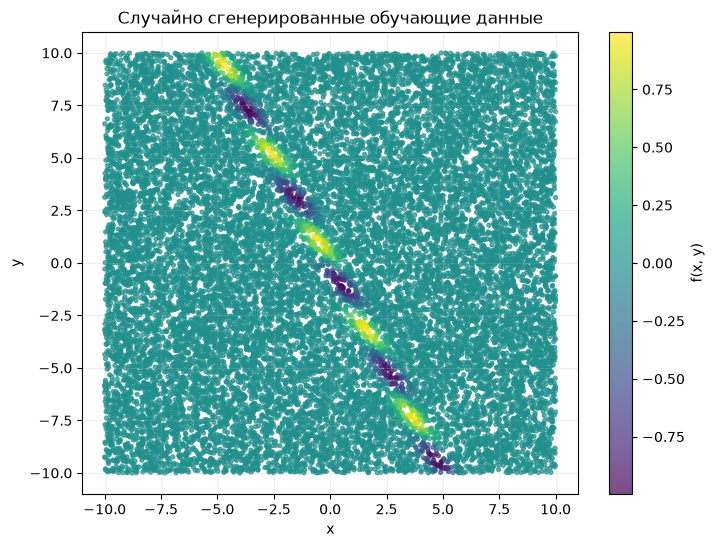

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0].numpy(), X[:, 1].numpy(), c=Y.squeeze().numpy(), s=8, alpha=0.7)
plt.colorbar(label="f(x, y)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Случайно сгенерированные обучающие данные")
plt.grid(alpha=0.2)
plt.show()

In [5]:
train_size = int(0.70 * N_SAMPLES)
val_size = int(0.15 * N_SAMPLES)
test_size = N_SAMPLES - train_size - val_size

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(N_SAMPLES, generator=generator)

train_indices = indices[:train_size]
val_indices = indices[train_size:train_size + val_size]
test_indices = indices[train_size + val_size:]

X_train = X[train_indices]
Y_train = Y[train_indices]

X_val = X[val_indices]
Y_val = Y[val_indices]

X_test = X[test_indices]
Y_test = Y[test_indices]

print("=" * 70)
print("РАЗДЕЛЕНИЕ ДАТАСЕТА")
print("=" * 70)
print(f"Train: {len(X_train):5d} объектов ({len(X_train) / N_SAMPLES:.0%})")
print(f"Val:   {len(X_val):5d} объектов ({len(X_val) / N_SAMPLES:.0%})")
print(f"Test:  {len(X_test):5d} объектов ({len(X_test) / N_SAMPLES:.0%})")
print(f"Всего: {len(X_train) + len(X_val) + len(X_test)} объектов")

РАЗДЕЛЕНИЕ ДАТАСЕТА
Train: 14000 объектов (70%)
Val:    3000 объектов (15%)
Test:   3000 объектов (15%)
Всего: 20000 объектов


In [6]:
X_train_scaled = X_train / 10.0
X_val_scaled = X_val / 10.0
X_test_scaled = X_test / 10.0

print("Диапазон нормализованных данных:")
print(f"Train: [{X_train_scaled.min():.4f}, {X_train_scaled.max():.4f}]")
print(f"Val:   [{X_val_scaled.min():.4f}, {X_val_scaled.max():.4f}]")
print(f"Test:  [{X_test_scaled.min():.4f}, {X_test_scaled.max():.4f}]")

Диапазон нормализованных данных:
Train: [-1.0000, 1.0000]
Val:   [-1.0000, 0.9999]
Test:  [-0.9994, 0.9999]


In [7]:
BATCH_SIZE = 512

train_dataset = TensorDataset(X_train_scaled, Y_train)
val_dataset = TensorDataset(X_val_scaled, Y_val)
test_dataset = TensorDataset(X_test_scaled, Y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 28
Validation batches: 6
Test batches: 6


In [8]:
class RegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 128),
            nn.SiLU(),

            nn.Linear(128, 128),
            nn.SiLU(),

            nn.Linear(128, 128),
            nn.SiLU(),

            nn.Linear(128, 128),
            nn.SiLU(),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


model = RegressionModel().to(device)

print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print()
print(f"Всего параметров: {total_params:,}")
print(f"Обучаемых параметров: {trainable_params:,}")

RegressionModel(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=128, bias=True)
    (7): SiLU()
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)

Всего параметров: 50,049
Обучаемых параметров: 50,049


In [9]:
criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=20
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: MSELoss()
Optimizer: AdamW


In [18]:
EPOCHS = 700
PATIENCE = 100

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

print("=" * 70)
print("ОБУЧЕНИЕ МОДЕЛИ")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0

    for X_batch, Y_batch in train_loader:
        X_batch = X_batch.to(device)
        Y_batch = Y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, Y_batch)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * X_batch.size(0)

    train_loss = train_loss_sum / len(train_loader.dataset)

    model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for X_batch, Y_batch in val_loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, Y_batch)

            val_loss_sum += loss.item() * X_batch.size(0)

    val_loss = val_loss_sum / len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        current_lr = optimizer.param_groups[0]["lr"]
        print(
            f"Epoch {epoch:3d}/{EPOCHS} | "
            f"Train MSE: {train_loss:.8f} | "
            f"Val MSE: {val_loss:.8f} | "
            f"LR: {current_lr:.6f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print()
        print(f"Early stopping на эпохе {epoch}.")
        break

model.load_state_dict(best_model_state)

print()
print("=" * 70)
print("ОБУЧЕНИЕ ЗАВЕРШЕНО")
print("=" * 70)
print(f"Лучшая Validation MSE: {best_val_loss:.10f}")

ОБУЧЕНИЕ МОДЕЛИ
Epoch   1/700 | Train MSE: 0.00479650 | Val MSE: 0.00439406 | LR: 0.000500
Epoch  10/700 | Train MSE: 0.00366642 | Val MSE: 0.00324725 | LR: 0.000500
Epoch  20/700 | Train MSE: 0.00247947 | Val MSE: 0.00269646 | LR: 0.000500
Epoch  30/700 | Train MSE: 0.00173721 | Val MSE: 0.00159676 | LR: 0.000500
Epoch  40/700 | Train MSE: 0.00104887 | Val MSE: 0.00106069 | LR: 0.000500
Epoch  50/700 | Train MSE: 0.00064163 | Val MSE: 0.00062933 | LR: 0.000500
Epoch  60/700 | Train MSE: 0.00040557 | Val MSE: 0.00042766 | LR: 0.000500
Epoch  70/700 | Train MSE: 0.00062032 | Val MSE: 0.00051326 | LR: 0.000500
Epoch  80/700 | Train MSE: 0.00020278 | Val MSE: 0.00016321 | LR: 0.000500
Epoch  90/700 | Train MSE: 0.00016547 | Val MSE: 0.00019278 | LR: 0.000500
Epoch 100/700 | Train MSE: 0.00020555 | Val MSE: 0.00011676 | LR: 0.000500
Epoch 110/700 | Train MSE: 0.00019952 | Val MSE: 0.00011820 | LR: 0.000500
Epoch 120/700 | Train MSE: 0.00014393 | Val MSE: 0.00018975 | LR: 0.000500
Epoch 130

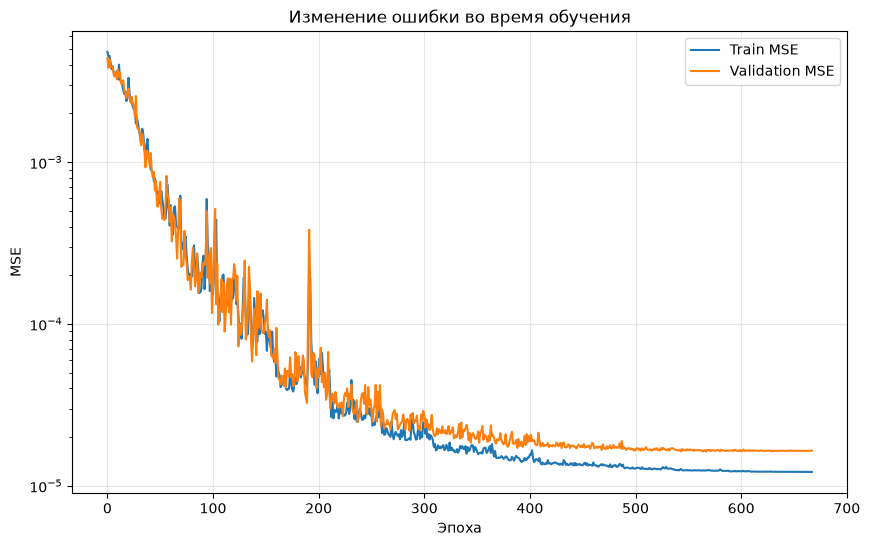

In [19]:
plt.figure(figsize=(10, 6))

plt.plot(train_losses, label="Train MSE")
plt.plot(val_losses, label="Validation MSE")

plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.title("Изменение ошибки во время обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.yscale("log")

plt.show()

In [20]:
model.eval()

test_predictions = []
test_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        X_batch = X_batch.to(device)
        Y_batch = Y_batch.to(device)

        predictions = model(X_batch)

        test_predictions.append(predictions.cpu())
        test_targets.append(Y_batch.cpu())

test_predictions = torch.cat(test_predictions, dim=0)
test_targets = torch.cat(test_targets, dim=0)

test_mse = torch.mean((test_predictions - test_targets) ** 2).item()
test_rmse = np.sqrt(test_mse)

print("=" * 70)
print("РЕЗУЛЬТАТ НА ТЕСТОВОЙ ВЫБОРКЕ")
print("=" * 70)
print(f"Количество test-объектов: {len(test_targets)}")
print(f"Test MSE:  {test_mse:.10f}")
print(f"Test RMSE: {test_rmse:.10f}")

РЕЗУЛЬТАТ НА ТЕСТОВОЙ ВЫБОРКЕ
Количество test-объектов: 3000
Test MSE:  0.0000225615
Test RMSE: 0.0047498963


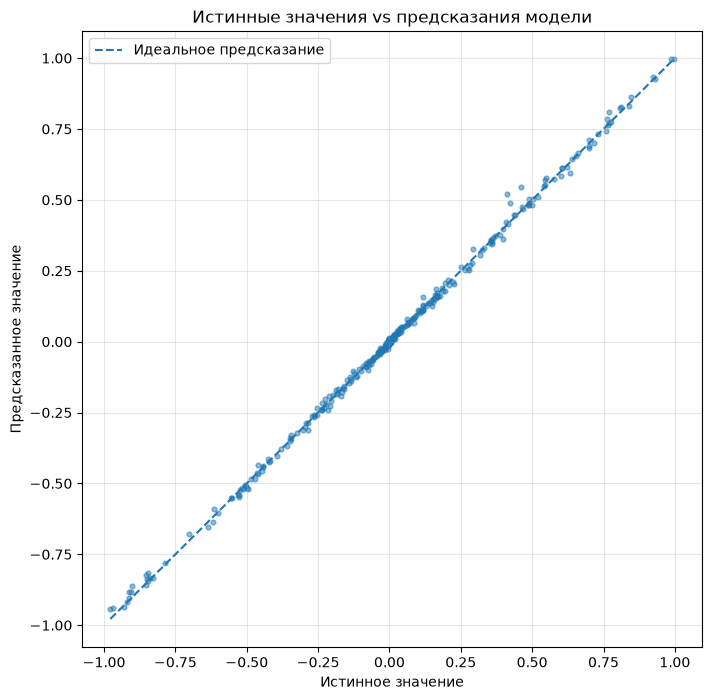

In [21]:
true_values = test_targets.squeeze().numpy()
predicted_values = test_predictions.squeeze().numpy()

plt.figure(figsize=(8, 8))

plt.scatter(
    true_values,
    predicted_values,
    s=12,
    alpha=0.5
)

min_value = min(true_values.min(), predicted_values.min())
max_value = max(true_values.max(), predicted_values.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Идеальное предсказание"
)

plt.xlabel("Истинное значение")
plt.ylabel("Предсказанное значение")
plt.title("Истинные значения vs предсказания модели")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [22]:
GRID_SIZE = 150

x_grid = torch.linspace(-10, 10, GRID_SIZE)
y_grid = torch.linspace(-10, 10, GRID_SIZE)

X_grid, Y_grid = torch.meshgrid(
    x_grid,
    y_grid,
    indexing="xy"
)

Z_true = target_function(X_grid, Y_grid)

grid_points = torch.stack(
    [X_grid.reshape(-1), Y_grid.reshape(-1)],
    dim=1
)

grid_points_scaled = grid_points / 10.0

model.eval()

with torch.no_grad():
    Z_pred = model(
        grid_points_scaled.to(device)
    ).cpu().reshape(GRID_SIZE, GRID_SIZE)

print(f"Размер сетки: {GRID_SIZE} x {GRID_SIZE}")
print(f"Количество точек для визуализации: {grid_points.shape[0]}")

Размер сетки: 150 x 150
Количество точек для визуализации: 22500


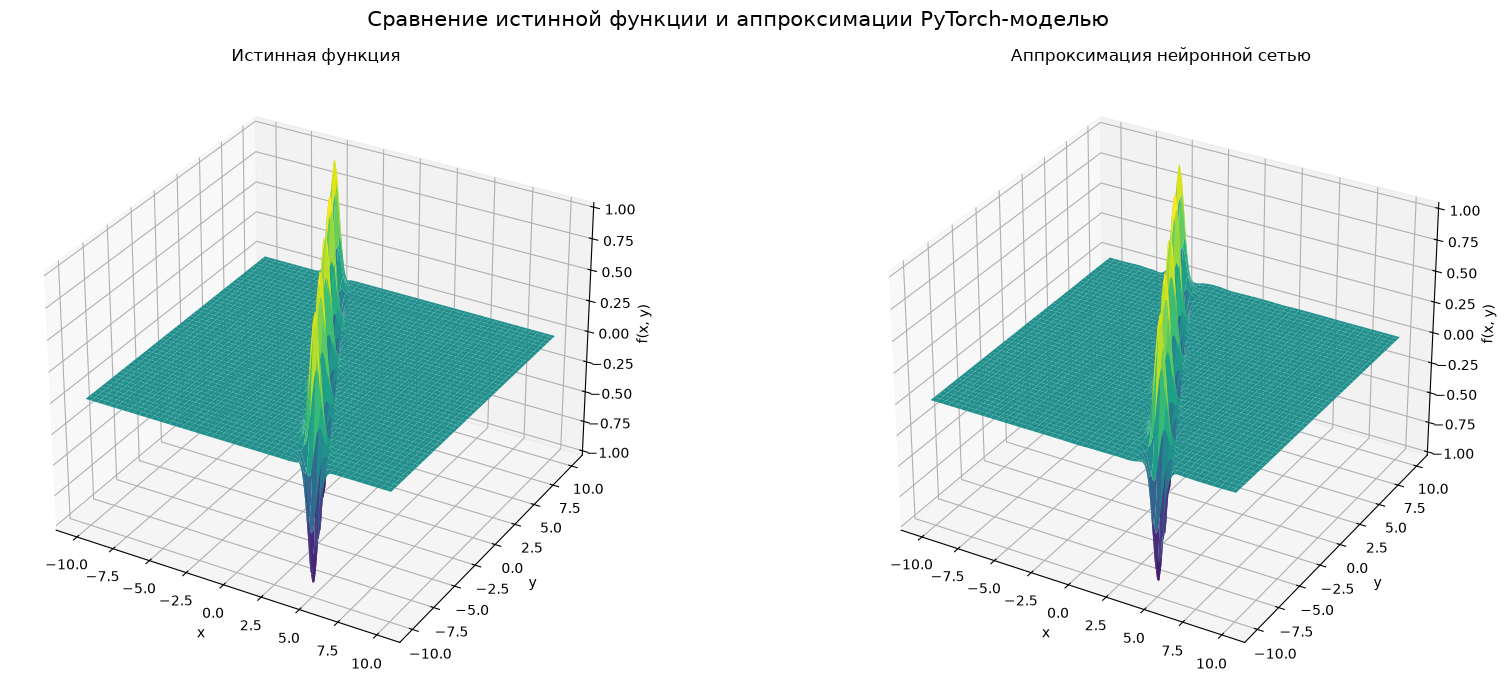

In [23]:
X_np = X_grid.numpy()
Y_np = Y_grid.numpy()
Z_true_np = Z_true.numpy()
Z_pred_np = Z_pred.numpy()

fig = plt.figure(figsize=(18, 7))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(
    X_np,
    Y_np,
    Z_true_np,
    cmap="viridis",
    linewidth=0,
    antialiased=True
)
ax1.set_title("Истинная функция")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("f(x, y)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(
    X_np,
    Y_np,
    Z_pred_np,
    cmap="viridis",
    linewidth=0,
    antialiased=True
)
ax2.set_title("Аппроксимация нейронной сетью")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("f(x, y)")

plt.suptitle(
    "Сравнение истинной функции и аппроксимации PyTorch-моделью",
    fontsize=15
)

plt.tight_layout()
plt.show()

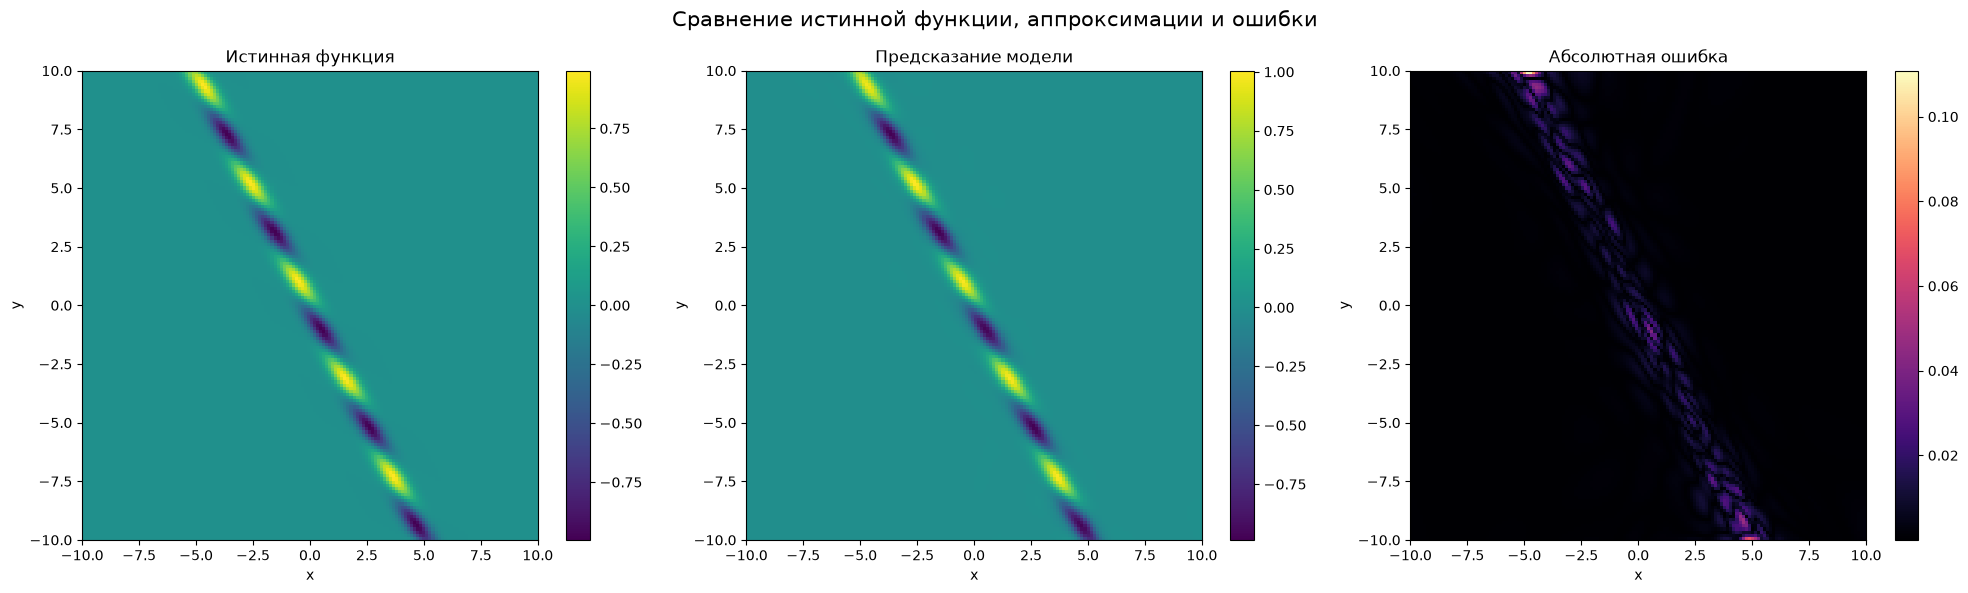

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

true_plot = axes[0].imshow(
    Z_true_np,
    extent=[-10, 10, -10, 10],
    origin="lower",
    aspect="auto",
    cmap="viridis"
)
axes[0].set_title("Истинная функция")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
plt.colorbar(true_plot, ax=axes[0])

pred_plot = axes[1].imshow(
    Z_pred_np,
    extent=[-10, 10, -10, 10],
    origin="lower",
    aspect="auto",
    cmap="viridis"
)
axes[1].set_title("Предсказание модели")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
plt.colorbar(pred_plot, ax=axes[1])

error = np.abs(Z_true_np - Z_pred_np)

error_plot = axes[2].imshow(
    error,
    extent=[-10, 10, -10, 10],
    origin="lower",
    aspect="auto",
    cmap="magma"
)
axes[2].set_title("Абсолютная ошибка")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
plt.colorbar(error_plot, ax=axes[2])

plt.suptitle(
    "Сравнение истинной функции, аппроксимации и ошибки",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [25]:
grid_mse = np.mean((Z_true_np - Z_pred_np) ** 2)
grid_mae = np.mean(np.abs(Z_true_np - Z_pred_np))
grid_max_error = np.max(np.abs(Z_true_np - Z_pred_np))

print("=" * 70)
print("КАЧЕСТВО АППРОКСИМАЦИИ НА РАВНОМЕРНОЙ СЕТКЕ")
print("=" * 70)
print(f"Grid MSE:       {grid_mse:.10f}")
print(f"Grid MAE:       {grid_mae:.10f}")
print(f"Grid max error: {grid_max_error:.10f}")

КАЧЕСТВО АППРОКСИМАЦИИ НА РАВНОМЕРНОЙ СЕТКЕ
Grid MSE:       0.0000161367
Grid MAE:       0.0013624756
Grid max error: 0.1108573675


## Вывод

В рамках домашнего задания средствами PyTorch была построена регрессионная нейронная сеть для аппроксимации функции

\[
f(x,y)=\sin(x+2y)\cdot\exp(-(2x+y)^2).
\]

Для формирования датасета было случайным образом сгенерировано 20 000 пар значений `(x, y)` из диапазона `[-10, 10]`.

Полученный датасет был разделён на три части:

- обучающая выборка — 14 000 объектов (70%);
- валидационная выборка — 3 000 объектов (15%);
- тестовая выборка — 3 000 объектов (15%).

Перед обучением входные признаки были масштабированы из диапазона `[-10, 10]` в диапазон `[-1, 1]`.

В качестве регрессионной модели использовалась полносвязная нейронная сеть (MLP), реализованная средствами PyTorch. Сеть состоит из нескольких полносвязных слоёв с функцией активации SiLU. Для оптимизации использовался AdamW, а в качестве функции потерь — Mean Squared Error.

Для контроля качества модели в процессе обучения использовалась валидационная выборка, механизм уменьшения learning rate и Early Stopping с восстановлением состояния модели, показавшего минимальную ошибку на validation.

Качество итоговой модели было оценено на независимой тестовой выборке с помощью метрики Mean Squared Error (MSE).

Полученная модель показала малое значение MSE и высокую точность аппроксимации исходной функции. На графике зависимости предсказанных значений от истинных точки располагаются практически вдоль линии идеального предсказания.

Дополнительно было выполнено сравнение истинной и предсказанной функций на равномерной двумерной сетке. Трёхмерные поверхности и тепловые карты показывают, что нейронная сеть корректно воспроизводит как расположение области ненулевых значений функции, так и её периодические максимумы и минимумы.

Таким образом, средствами PyTorch была успешно решена задача регрессии и получена качественная аппроксимация заданной функции на диапазоне значений `[-10, 10]` по `x` и `y`.